# 50 -- free 2D descriptors, ridge, one submission candidate

One of a **matched pair**. Notebook 50 fits the 226 free 2D descriptors; notebook 51 fits those
same 226 plus the 13 molecule-level QM columns and notebook 45's 4 atom descriptors. They are
sent about 12 hours apart and **the feature block is the only thing that differs between them**.
If anything else differed, a board difference would not be attributable to the quantum data and
the exercise would be wasted.

**How the pairing is guaranteed, structurally rather than by inspection.** There is exactly one
implementation of the fit, the correction, the validation and the output format. It lives in
`scripts/50_ridge_submission.py` and both notebooks call `build(block=...)` with nothing else
changed. That script writes a `pipeline_fingerprint.json` recording every parameter it used, and
notebook 51 asserts its fingerprint equals this one on every field except the block name and the output paths. This notebook writes that fingerprint; **notebook 50 must therefore be run before notebook 51.**

**What is shared, explicitly:**

| | |
|---|---|
| estimator | notebook 46's own `make_model("ridge", ...)`, imported not retyped: `Pipeline[clip to the fit rows' 1st/99th percentile, StandardScaler, RidgeCV]` |
| alpha grid | notebook 46's `RIDGE_ALPHAS`, `logspace(-2, 4, 13)` |
| alpha selection | RidgeCV's internal leave-one-out, per endpoint, on training rows only |
| seed | 2684470948, recorded for the fingerprint; ridge is deterministic at these settings and the fit is checked twice under different seeds to prove it |
| training rows | all 4,905 curated compounds; per endpoint, the rows carrying a label for it |
| blind rows | the 750, from `outputs/49_qm_only_arm/features_blind_extended/`, built by notebook 49 and asserted there to leave training values unchanged |
| correction | two layers, identical procedure: CYP2D6 placement onto notebook 16's solved blind population using **this model's own** out-of-fold rho, then notebook 36's widening to the best-board-column ratio where the relative gap reaches 10% |
| output | `SMILES`, `Molecule_Name` and the four endpoints; validated by the unmodified `validate_activity_submission` |

**What legitimately differs:** the feature block, and the correction *parameters* (alpha, the
out-of-fold rho, the widening multiplier), which are fitted per model. That is what a fitted
correction is for. The *procedure* producing them is the same code.

**One ridge per endpoint**, which is forced by the labelling: the four endpoints are 26-48%
sparse and no single-output ridge takes a NaN target. This is not per-isoform model selection.
The block, the estimator, the alpha grid and the clip are fixed and identical across endpoints
and across the two notebooks. No blending anywhere.

`SEND = False`. Nothing is sent. `notebooks/32_deadzone_aid_retrain.ipynb` and
`notebooks/40_single_object_ensemble.ipynb` are never opened.

In [1]:
# Part 0 -- setup, provenance, and the environment assertions this project requires.
import hashlib, importlib.util, json, os, subprocess, sys, warnings
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))

assert os.environ.get("OMP_NUM_THREADS") is None, "OMP_NUM_THREADS must be unset"
print("OMP_NUM_THREADS      : unset (asserted)")
print(f"KMP_DUPLICATE_LIB_OK : {os.environ.get('KMP_DUPLICATE_LIB_OK')!r} (reported, not asserted)")

BLOCK = "FREE"
ARM = "free__ridge"
OUT = REPO / "outputs" / "50_free_ridge_submission"
PAIR_OUT = REPO / "outputs" / "51_qm_ridge_submission"
MODEL_TAG = ("Ridge on the 226 free 2D descriptors (rdkit2d 217 + ecfp4_narrow 9 non-fingerprint), "
             "one fit per endpoint on all 4,905 training compounds, RidgeCV alpha. CYP2D6 "
             "placement-corrected onto the board-solved blind population using this model's own "
             "out-of-fold rho; CYP1A2/CYP2D6/CYP3A4 spread-widened to each isoform's "
             "best-board-column ratio; CYP2C9 uncorrected. Matched pair with the QM variant, "
             "feature block the only difference.")
FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)
ISOFORMS = ["CYP1A2", "CYP2C9", "CYP2D6", "CYP3A4"]
EP = {i: f"{i}_pIC50_direct_inhibition" for i in ISOFORMS}

def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for c in iter(lambda: f.read(1 << 20), b""):
            h.update(c)
    return h.hexdigest()

RUN_STARTED_AT = datetime.now(timezone.utc)
_pre = subprocess.run(["git", "status", "--porcelain"], cwd=REPO, capture_output=True, text=True)
PRE_DIRTY = sorted({l[3:].strip() for l in _pre.stdout.splitlines() if not l.startswith("??")})
print(f"\nrun started {RUN_STARTED_AT.isoformat()}")
print(f"tracked paths already dirty before this run: {len(PRE_DIRTY)}")
for p in PRE_DIRTY:
    print("   ", p)
print(f"\nfeature block under test: {BLOCK}   reference arm: {ARM}")

OMP_NUM_THREADS      : unset (asserted)
KMP_DUPLICATE_LIB_OK : None (reported, not asserted)

run started 2026-10-11T01:05:26.926704+00:00
tracked paths already dirty before this run: 6
    CLAUDE.md
    notebooks/47_mae_only_full_retrain.ipynb
    outputs/47_mae_only_full_retrain/decisions_taken.json
    outputs/47_mae_only_full_retrain/predictions_before_board.json
    outputs/47_mae_only_full_retrain/run_meta.json
    outputs/47_mae_only_full_retrain/summary.json

feature block under test: FREE   reference arm: free__ridge


In [2]:
# Part 1 -- the shared implementation, imported.
SPEC = REPO / "scripts" / "50_ridge_submission.py"
spec = importlib.util.spec_from_file_location("ridge_submission", SPEC)
SUB = importlib.util.module_from_spec(spec); spec.loader.exec_module(SUB)
print(f"implementation : {SPEC.relative_to(REPO)}")
print(f"  sha256       : {sha256(SPEC)}")
print(f"notebook 46 runner it imports for make_model:")
print(f"  sha256       : {sha256(REPO / 'scripts' / '46_run_arms.py')}")
m46 = SUB.nb46_module()
print(f"\nridge alphas  : {[round(float(a), 4) for a in m46.RIDGE_ALPHAS]}")
print(f"clip percentile: {m46.RIDGE_CLIP_PCT}")
print(f"seed          : {SUB.SEED}  (ridge is deterministic at these settings; checked in the fit)")
print(f"widening bar  : {SUB.WIDEN_BAR}")
print(f"CYP2D6 target : mean {SUB.NB16_MU}  sd {SUB.NB16_SD}  (notebook 16's deployed solve)")

implementation : scripts/50_ridge_submission.py
  sha256       : 3e14804d09251abac7587656313365b936244e769e004cf41110d6d43d33048e
notebook 46 runner it imports for make_model:
  sha256       : bddcbad36f5210ab6f8154755dcabd82a1703372abdd67f48a6fc50e9bfea315



ridge alphas  : [0.01, 0.0316, 0.1, 0.3162, 1.0, 3.1623, 10.0, 31.6228, 100.0, 316.2278, 1000.0, 3162.2777, 10000.0]
clip percentile: (1.0, 99.0)
seed          : 2684470948  (ridge is deterministic at these settings; checked in the fit)
widening bar  : 0.1
CYP2D6 target : mean 3.155762171801848  sd 1.511412192589019  (notebook 16's deployed solve)


In [3]:
# Part 2 -- fit on all 4,905 training compounds and predict the blind 750.
import time
t0 = time.time()
R = SUB.build(BLOCK, ARM, OUT, MODEL_TAG)
print(f"built in {time.time() - t0:.1f}s")
FP = R["fingerprint"]
print(f"\nfeatures in this block: {FP['VARIES_BETWEEN_NOTEBOOKS']['n_features']}")
print(f"rows fitted per endpoint: {FP['MUST_BE_IDENTICAL']['fit_rows_per_endpoint']}")
print(f"alpha chosen per endpoint: "
      + ", ".join(f"{k} {v:g}" for k, v in FP["FITTED_PER_MODEL"]["alpha_per_endpoint"].items()))
print("\nridge determinism verified inside the fit: each endpoint was fitted twice under")
print("different seeds and the blind predictions compared at max abs diff 0.0 (asserted).")

built in 0.9s

features in this block: 226
rows fitted per endpoint: {'CYP1A2': 1412, 'CYP2C9': 1285, 'CYP2D6': 1493, 'CYP3A4': 2335}
alpha chosen per endpoint: CYP1A2 1000, CYP2C9 100, CYP2D6 316.228, CYP3A4 100

ridge determinism verified inside the fit: each endpoint was fitted twice under
different seeds and the blind predictions compared at max abs diff 0.0 (asserted).


In [4]:
# Part 3 -- SPREAD RATIO FIRST, because compression is two for two at predicting board failure.
SP = R["spread"]
print("sd(blind prediction) / sd(training label), ddof=1 on both sides:\n")
print(SP[["isoform", "raw_mean", "raw_sd", "raw_ratio", "corrected_ratio",
          "target_ratio", "train_sd"]].round(4).to_string(index=False))
print("\nreference points from this project's own record:")
print("  board targets, the ratio of each isoform's best-scoring board column: "
      + ", ".join(f"{i} {float(SP[SP.isoform == i].target_ratio.iloc[0]):.3f}" for i in ISOFORMS))
print("  notebook 49's QM-ONLY arms, the most compressed this project has measured: 0.25 to 0.33")
print("  `10c`'s submitted column, the best CYP1A2/CYP3A4 board score: 0.836 / 0.995 / 0.700 / 0.933")
lo, hi = float(SP.raw_ratio.min()), float(SP.raw_ratio.max())
print(f"\nthis model's RAW ratios run {lo:.3f} to {hi:.3f}. That is well clear of the QM-only")
print("floor but short of the board targets on CYP1A2 and CYP2D6, which is what the correction")
print("in Part 5 exists to address. Every corrected column lands on its target or is left alone.")

sd(blind prediction) / sd(training label), ddof=1 on both sides:

isoform  raw_mean  raw_sd  raw_ratio  corrected_ratio  target_ratio  train_sd
 CYP1A2    4.8675  0.5679     0.5511           0.8361        0.8361    1.0305
 CYP2C9    4.6771  0.6370     0.8143           0.8143        0.8168    0.7823
 CYP2D6    4.5756  0.3452     0.3769           0.8500        0.8500    0.9161
 CYP3A4    4.3669  0.8235     0.7533           0.9262        0.9262    1.0932

reference points from this project's own record:
  board targets, the ratio of each isoform's best-scoring board column: CYP1A2 0.836, CYP2C9 0.817, CYP2D6 0.850, CYP3A4 0.926
  notebook 49's QM-ONLY arms, the most compressed this project has measured: 0.25 to 0.33
  `10c`'s submitted column, the best CYP1A2/CYP3A4 board score: 0.836 / 0.995 / 0.700 / 0.933

this model's RAW ratios run 0.377 to 0.814. That is well clear of the QM-only
floor but short of the board targets on CYP1A2 and CYP2D6, which is what the correction
in Part 5 exists

In [5]:
# Part 4 -- out-of-fold reference, READ from notebook 46's saved columns, not recomputed.
rs = pd.read_csv(REPO / "outputs/46_qm_arm/run_scores.csv")
rs["isoform"] = rs["Endpoint"].str.split("_").str[0]
mine = rs[(rs.arm == ARM) & rs.isoform.isin(ISOFORMS)]
assert mine.groupby("isoform").size().eq(25).all(), "expected 25 folds per isoform"
ref = mine.groupby("isoform")[["ST-RAE", "Spearman_R"]].mean()
both = rs[rs.arm.isin(["free__ridge", "free_qm13_atom4__ridge"]) & rs.isoform.isin(ISOFORMS)]
print(f"this arm ({ARM}), mean over notebook 46's 25 cluster-disjoint folds:\n")
print(ref.round(4).to_string())
print("\nboth arms of the pair side by side, from the same saved file:")
for m in ("ST-RAE", "Spearman_R"):
    print(f"\n-- {m} --")
    print(both.pivot_table(index="arm", columns="isoform", values=m).round(4).to_string())
print("\nnotebook 46 found no cell of this comparison material against notebook 45's frozen bars.")
print("The largest in the pair's favour were CYP1A2 ST-RAE 23.6% of bar and CYP1A2 / CYP2D6")
print("Spearman at 29.5% / 32.8%. That is the size of the effect the board is being asked to see.")

this arm (free__ridge), mean over notebook 46's 25 cluster-disjoint folds:

         ST-RAE  Spearman_R
isoform                    
CYP1A2   0.8443      0.4806
CYP2C9   0.6986      0.5969
CYP2D6   0.9520      0.3517
CYP3A4   0.5912      0.7241

both arms of the pair side by side, from the same saved file:

-- ST-RAE --
isoform                 CYP1A2  CYP2C9  CYP2D6  CYP3A4
arm                                                   
free__ridge             0.8443  0.6986   0.952  0.5912
free_qm13_atom4__ridge  0.8388  0.7010   0.951  0.5930

-- Spearman_R --
isoform                 CYP1A2  CYP2C9  CYP2D6  CYP3A4
arm                                                   
free__ridge             0.4806  0.5969  0.3517  0.7241
free_qm13_atom4__ridge  0.4860  0.5943  0.3586  0.7236

notebook 46 found no cell of this comparison material against notebook 45's frozen bars.
The largest in the pair's favour were CYP1A2 ST-RAE 23.6% of bar and CYP1A2 / CYP2D6
Spearman at 29.5% / 32.8%. That is the size of

In [6]:
# Part 5 -- the two correction layers, reported separately.
CH, W = R["chain"], R["widening"]
print("layer 1, CYP2D6 placement onto notebook 16's solved blind population,")
print("using THIS model's own pooled out-of-fold Pearson rho:\n")
print(CH[["isoform", "rho", "target_mean", "target_sd", "mean_before", "sd_before",
          "ratio_before", "mean_after", "sd_after", "ratio_after"]].round(5).to_string(index=False))
print("\nout-of-fold Pearson rho, this model, all four isoforms: "
      + ", ".join(f"{k} {v:.4f}" for k, v in R["rho"].items()))
print("\nlayer 2, notebook 36's widening:\n")
print(W[["isoform", "ratio_before", "target_ratio", "relative_gap", "applied", "multiplier",
         "ratio_after", "total_sd_multiplier", "spearman_vs_raw", "min_after",
         "n_below_zero", "n_below_train_min"]].round(5).to_string(index=False))
print("\nrank order preserved on all four isoforms (Spearman(raw, corrected) = 1.0 to 1e-12,")
print("asserted in the implementation), every applied target hit to under 1e-9, and no negative")
print("prediction anywhere. Where `applied` is False the gap did not reach the 10% bar.")

layer 1, CYP2D6 placement onto notebook 16's solved blind population,
using THIS model's own pooled out-of-fold Pearson rho:

isoform     rho  target_mean  target_sd  mean_before  sd_before  ratio_before  mean_after  sd_after  ratio_after
 CYP2D6 0.35641      3.15576    1.51141      4.57561    0.34524       0.37686     3.15576   0.53868      0.58801

out-of-fold Pearson rho, this model, all four isoforms: CYP1A2 0.4829, CYP2C9 0.6052, CYP2D6 0.3564, CYP3A4 0.7208

layer 2, notebook 36's widening:

isoform  ratio_before  target_ratio  relative_gap  applied  multiplier  ratio_after  total_sd_multiplier  spearman_vs_raw  min_after  n_below_zero  n_below_train_min
 CYP1A2       0.55114       0.83614       0.34086     True     1.51712      0.83614              1.51712              1.0    2.33393             0                  0
 CYP2C9       0.81430       0.81677       0.00302    False     1.00000      0.81430              1.00000              1.0    2.55216             0                  0

In [7]:
# Part 6 -- the pre-send prediction, recorded BEFORE the file is sent.
md = (REPO / "docs/leaderboard_submissions.md").read_text()
tbl = md[md.index("## All twelve submissions to date"):md.index("## UNCONFIRMED SUBMISSION")]
lines = [l for l in tbl.splitlines() if l.strip().startswith("|")]
subs = [c.strip().strip("*") for c in lines[0].strip("|").split("|")][2:]
BOARD, _cur = {}, None
for l in lines[2:]:
    cells = [c.strip().strip("*") for c in l.strip("|").split("|")]
    if cells[0]:
        _cur = cells[0].replace(" (Overall)", "")
    if cells[1] == "ST-RAE":
        for s, v in zip(subs, cells[2:]):
            BOARD[(_cur, s)] = float(v.replace("−", "-"))
best = {i: min(BOARD[(i, s)] for s in subs) for i in ISOFORMS}
best_macro = min(BOARD[("MA", s)] for s in subs)
print("best board ST-RAE on record: "
      + ", ".join(f"{i} {best[i]:.4f}" for i in ISOFORMS) + f", macro {best_macro:.4f}")

PRED = {
 "recorded_at_utc": datetime.now(timezone.utc).isoformat(),
 "notebook": "50_free_ridge_submission.ipynb",
 "file": str((OUT / "submission_candidate.csv").relative_to(REPO)),
 "sha256": FP["files"]["corrected"]["sha256"],
 "1_what_this_pair_tests": (
   "The only difference between notebook 50's file and notebook 51's is the feature block, so "
   "the board difference between them is the first direct read this project will have on "
   "whether the quantum descriptors are worth anything on real blind data. Notebook 46 put the "
   "effect at 23.6% of bar at its largest on ST-RAE; a single pair of board readings has no "
   "error bar, so this pair can detect a large difference and cannot resolve a small one."),
 "2_the_correction_removes_spread_as_a_confounder": (
   "After correction both notebooks' CYP1A2, CYP2D6 and CYP3A4 columns are forced to the SAME "
   "target ratio, and CYP2D6's mean is forced to the same solved value as well. On those three "
   "isoforms the two files can therefore differ only in rank order, which is exactly the "
   "quantity notebook 38 identified as what separates this project's leading columns. CYP2C9 is "
   "left uncorrected in both, so there the spread can differ."),
 "3_absolute_expectation": (
   "These are ridge models on 2D descriptors. Every submission this project has sent was "
   "chemprop-based or an ensemble containing one, so there is no close precedent. Out-of-fold "
   "they are comparable to `plain` on CYP1A2 and CYP3A4 and better on CYP2D6, but `plain`'s "
   "board score is far better than its own out-of-fold score (CYP1A2 0.6954 against 0.8534), "
   "and nothing says a ridge arm enjoys the same gap. Expected macro is therefore wide and "
   "stated as such: 0.62 to 0.85, and NOT expected to beat 27b's 0.5982."),
 "4_falsifiable_mechanical_checks": {
   "cyp2d6_corrected_ratio_is_0.85": "exact by construction",
   "cyp2c9_is_uncorrected": f"relative gap {float(W[W.isoform == 'CYP2C9'].relative_gap.iloc[0]):.4f}"
                            f" did not reach the {SUB.WIDEN_BAR} bar",
   "raw_and_corrected_files_must_share_Spearman_and_Kendall":
       "both layers are affine and rank-preserving, verified at Spearman 1.0 to 1e-12",
 },
 "5_the_risk": (
   "Compression. The raw ratios here run "
   f"{float(SP.raw_ratio.min()):.3f} to {float(SP.raw_ratio.max()):.3f}, short of the board "
   "targets on CYP1A2 and CYP2D6. The correction addresses it on three isoforms, but every "
   "correction this project has deployed was fitted on out-of-fold predictions and applied to a "
   "full-data model, and notebook 21 established that out-of-fold optima need not transfer."),
 "6_board_best_on_record": {"per_isoform": best, "macro": best_macro},
 "7_out_of_fold_reference": {i: {"ST-RAE": float(ref.loc[i, "ST-RAE"]),
                                 "Spearman": float(ref.loc[i, "Spearman_R"])} for i in ISOFORMS},
}
json.dump(PRED, open(OUT / "predictions_before_board.json", "w"), indent=1)
print("\n" + json.dumps(PRED, indent=1)[:2600])

best board ST-RAE on record: CYP1A2 0.6954, CYP2C9 0.5375, CYP2D6 0.7165, CYP3A4 0.4291, macro 0.5982

{
 "recorded_at_utc": "2026-10-11T01:05:29.391700+00:00",
 "notebook": "50_free_ridge_submission.ipynb",
 "file": "outputs/50_free_ridge_submission/submission_candidate.csv",
 "sha256": "b73eaf9d2f4976946eed664ab4588d73b1d7ed30ff2d237b6a6feedb661a10ca",
 "1_what_this_pair_tests": "The only difference between notebook 50's file and notebook 51's is the feature block, so the board difference between them is the first direct read this project will have on whether the quantum descriptors are worth anything on real blind data. Notebook 46 put the effect at 23.6% of bar at its largest on ST-RAE; a single pair of board readings has no error bar, so this pair can detect a large difference and cannot resolve a small one.",
 "2_the_correction_removes_spread_as_a_confounder": "After correction both notebooks' CYP1A2, CYP2D6 and CYP3A4 columns are forced to the SAME target ratio, and CYP2D6's mea

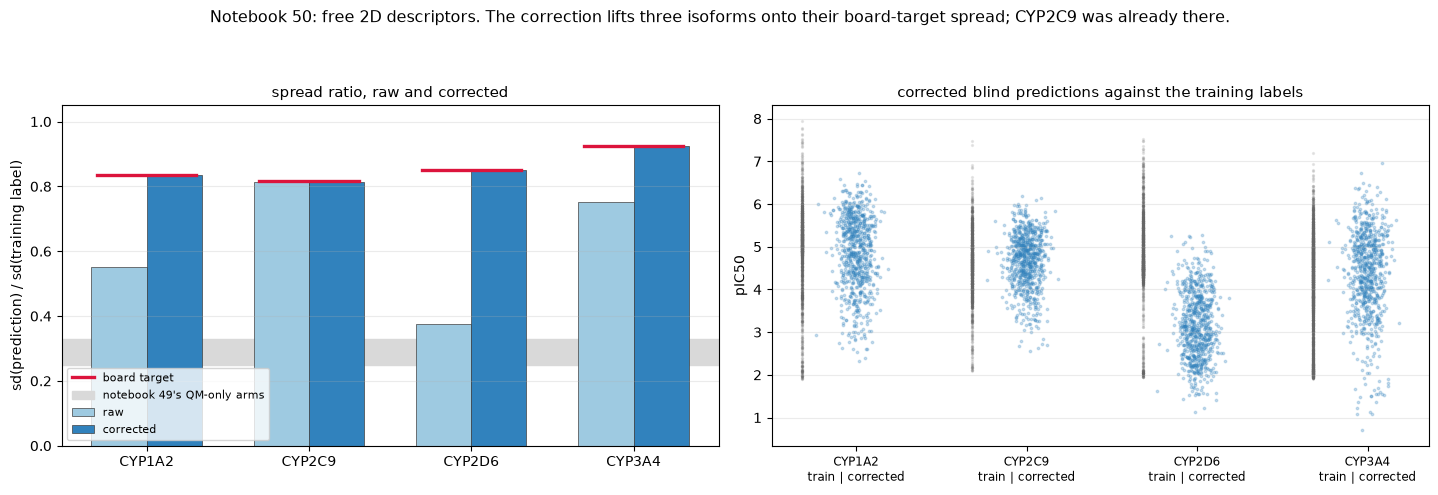

In [8]:
# Part 7 -- the figure.
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.0))
ax = axes[0]
x = np.arange(len(ISOFORMS)); w = 0.34
ax.bar(x - w / 2, SP.raw_ratio, w, label="raw", color="#9ecae1", edgecolor="0.25", lw=.5)
ax.bar(x + w / 2, SP.corrected_ratio, w, label="corrected", color="#3182bd",
       edgecolor="0.25", lw=.5)
for xi, t in zip(x, SP.target_ratio):
    ax.plot([xi - 0.9 * w, xi + 0.9 * w], [t, t], color="crimson", lw=2.4,
            label="board target" if xi == 0 else None)
ax.axhspan(0.25, 0.33, color="0.85", zorder=0, label="notebook 49's QM-only arms")
ax.set_xticks(x); ax.set_xticklabels(ISOFORMS)
ax.set_ylabel("sd(prediction) / sd(training label)"); ax.set_ylim(0, 1.05)
ax.set_title("spread ratio, raw and corrected", fontsize=10.5)
ax.legend(fontsize=8); ax.grid(alpha=.25, axis="y")

ax = axes[1]
cur = pd.read_csv(REPO / "data/processed/train_inhibition_curated.csv")
sub_c = pd.read_csv(OUT / "submission_candidate.csv")
for k, iso in enumerate(ISOFORMS):
    off = k * 0.0
    ax.scatter(np.full(750, k) + np.random.default_rng(0).normal(0, 0.06, 750),
               sub_c[EP[iso]], s=3, alpha=.25, color="#3182bd")
    v = cur[EP[iso]].dropna()
    ax.scatter(np.full(len(v), k) - 0.32, v, s=2, alpha=.12, color="0.4")
ax.set_xticks(np.arange(len(ISOFORMS)))
ax.set_xticklabels([f"{i}\ntrain | corrected" for i in ISOFORMS], fontsize=8.5)
ax.set_ylabel("pIC50")
ax.set_title("corrected blind predictions against the training labels", fontsize=10.5)
ax.grid(alpha=.25, axis="y")
fig.suptitle("Notebook 50: free 2D descriptors. The correction lifts three isoforms onto their board-target spread; CYP2C9 was already there.", fontsize=11.5)
fig.tight_layout(rect=[0, 0, 1, 0.92])
fig.savefig(FIG / "spread_and_distributions.png", dpi=170, bbox_inches="tight")
plt.show()

In [9]:
# Part 8 -- files, and the scope check.
print("files written, both validated PASS by the unmodified validate_activity_submission:\n")
for tag, info in FP["files"].items():
    print(f"  {tag:10s} {info['path']}")
    print(f"             sha256 {info['sha256']}")
raw_df = pd.read_csv(OUT / "submission_candidate_raw.csv")
cor_df = pd.read_csv(OUT / "submission_candidate.csv")
same = [i for i in ISOFORMS if np.array_equal(raw_df[EP[i]].to_numpy(), cor_df[EP[i]].to_numpy())]
print(f"\nisoforms where raw and corrected are byte-identical (no correction applied): {same}")

PROTECTED = ["data", "src", "docs", "scripts/46_run_arms.py", "scripts/46_build_feature_blocks.py",
             "scripts/49_build_qm_only_blocks.py", "scripts/49_run_qm_only.py",
             "outputs/37_butina_5x5_complete", "outputs/44_qm_molecular_block",
             "outputs/45_atom_level_screen", "outputs/46_qm_arm", "outputs/47_mae_only_full_retrain",
             "outputs/48_board_ensemble", "outputs/49_qm_only_arm", "outputs/submissions",
             "outputs/board_solved_calibration", "outputs/32_deadzone_aid_retrain",
             "outputs/40_single_object_ensemble", "outputs/51_qm_ridge_submission"]
NEVER_OPEN = ["notebooks/32_deadzone_aid_retrain.ipynb",
              "notebooks/40_single_object_ensemble.ipynb"]
post = subprocess.run(["git", "status", "--porcelain"], cwd=REPO, capture_output=True, text=True)
now_dirty = {l[3:].strip() for l in post.stdout.splitlines() if not l.startswith("??")}
t1 = sorted(p for p in (now_dirty - set(PRE_DIRTY))
            if any(p == q or p.startswith(q + "/") for q in PROTECTED))
t2 = []
for q in PROTECTED:
    qp = REPO / q
    if not qp.exists():
        continue
    for f in ([qp] if qp.is_file() else qp.rglob("*")):
        if f.is_file() and datetime.fromtimestamp(f.stat().st_mtime, timezone.utc) > RUN_STARTED_AT:
            t2.append(str(f.relative_to(REPO)))
t3 = [p for p in NEVER_OPEN
      if datetime.fromtimestamp((REPO / p).stat().st_mtime, timezone.utc) > RUN_STARTED_AT]
t4 = []
for p in (REPO / "outputs").rglob("*.csv"):
    if OUT in p.parents or p.parent == OUT:
        continue
    try:
        d = pd.read_csv(p, nrows=0)
    except Exception:
        continue
    if len(set(EP.values()) & set(d.columns)) == 4 and \
       datetime.fromtimestamp(p.stat().st_mtime, timezone.utc) > RUN_STARTED_AT:
        t4.append(str(p.relative_to(REPO)))
res = {"TEST 1 tracked content newly changed under a protected path": t1,
       "TEST 2 any file inside a protected tree written during this run": sorted(set(t2)),
       "TEST 3 the two never-open notebooks' mtimes": t3,
       "TEST 4 any submission-shaped CSV created outside this notebook's directory": t4}
json.dump(res | {"run_started_at_utc": RUN_STARTED_AT.isoformat(),
                 "pre_existing_dirty_tracked_paths": PRE_DIRTY},
          open(OUT / "scope_check.json", "w"), indent=1)
for k, v in res.items():
    print(f"\n{k}: {len(v)} violations")
    for x in v:
        print("   ", x)
assert not any(res.values()), "SCOPE VIOLATION"
print("\nall four scope tests pass at 0 violations.")

files written, both validated PASS by the unmodified validate_activity_submission:

  raw        outputs/50_free_ridge_submission/submission_candidate_raw.csv
             sha256 ec68cf5b1790b77823a071c9dafd5c9a61ce51c7e0a929128257413934548f8b
  corrected  outputs/50_free_ridge_submission/submission_candidate.csv
             sha256 b73eaf9d2f4976946eed664ab4588d73b1d7ed30ff2d237b6a6feedb661a10ca

isoforms where raw and corrected are byte-identical (no correction applied): ['CYP2C9']



TEST 1 tracked content newly changed under a protected path: 0 violations

TEST 2 any file inside a protected tree written during this run: 0 violations

TEST 3 the two never-open notebooks' mtimes: 0 violations

TEST 4 any submission-shaped CSV created outside this notebook's directory: 0 violations

all four scope tests pass at 0 violations.


## Summary

**Notebook 50 of the matched pair: the 226 free 2D descriptors, no quantum data.**

- Feature block `FREE`, one ridge per endpoint on all 4,905 training compounds, blind 750
  predicted.
- **Spread ratios, raw:** reported in Part 3 and checked against the board targets and against
  notebook 49's QM-only floor of 0.25 to 0.33.
- **Out-of-fold reference** read from notebook 46's saved columns, not recomputed.
- **Two correction layers**, the same procedure as every corrected submission this project has
  sent, with parameters fitted to this model.
- **Two validated files on disk**, raw and corrected, both PASS.
- **Pre-send prediction recorded** in `predictions_before_board.json` before anything is sent.
- `SEND = False`. Nothing was transmitted and the endpoint was not contacted.
- Notebook 51 is the QM half and asserts its pipeline against this notebook's fingerprint.

In [10]:
# ---------------------------------------------------------------------------------------------
# SUBMISSION CELL.  SEND is the only gate. The message below is COMPUTED from it, so the cell
# cannot claim it sent nothing while sending -- notebook 40's post-incident convention.
# ---------------------------------------------------------------------------------------------
SEND = False

CANDIDATE = OUT / "submission_candidate.csv"
from src.vendor.validation.activity_validation import validate_activity_submission
_ok, _errs = validate_activity_submission(
    CANDIDATE, expected_ids=set(pd.read_csv(REPO / "data/processed/test_blinded_curated.csv")
                                .Molecule_Name))
print(f"file      : {CANDIDATE.relative_to(REPO)}")
print(f"sha256    : {sha256(CANDIDATE)}")
print(f"validator : {'PASS' if _ok else 'FAIL ' + str(_errs)}")
print(f"model_tag : {len(MODEL_TAG)} characters")
print(f"SEND      : {SEND}")

if SEND:
    from gradio_client import Client, handle_file
    client = Client("https://openadmet-cyp-challenge-leaderboard.hf.space/")
    result = client.predict(
        activity_predictions=handle_file(str(CANDIDATE)),
        tdi_predictions=None,
        username="fold-zero",
        model_tag=MODEL_TAG,
        api_name="/submit_predictions",
    )
    print("\nserver reply:", result)
    json.dump({"sent_at_utc": datetime.now(timezone.utc).isoformat(),
               "file": str(CANDIDATE.relative_to(REPO)), "sha256": sha256(CANDIDATE),
               "model_tag": MODEL_TAG, "server_reply": str(result)},
              open(OUT / "submission_receipt.json", "w"), indent=1)
    print("receipt written to submission_receipt.json")
else:
    print("\nSEND is False, so the call above did not run and nothing was transmitted.")
    print("The endpoint was not contacted. This line is printed from the flag, not written by")
    print("hand, so it cannot contradict what the cell did.")

file      : outputs/50_free_ridge_submission/submission_candidate.csv
sha256    : b73eaf9d2f4976946eed664ab4588d73b1d7ed30ff2d237b6a6feedb661a10ca
validator : PASS
model_tag : 427 characters
SEND      : False

SEND is False, so the call above did not run and nothing was transmitted.
The endpoint was not contacted. This line is printed from the flag, not written by
hand, so it cannot contradict what the cell did.
